# axis_kidsim_v3 — resonator characterization

Demonstrates the KID/qubit resonator emulator and validates the IIR↔resonator
mapping from the design note. Five measurements (design-note §7):

1. **Linewidth / Q** — sweep the probe, fit the notch, recover $\kappa$, $Q$ [1][2].
2. **Ringdown** — drive on resonance, cut the drive, fit $\tau=1/(-\ln C_1\,f_s)$ [3].
3. **Notch depth vs coupling** — sweep $\kappa_c$, confirm depth $=\kappa_c/\kappa$.
4. **The jump** — switch ground→excited mid-trace; watch the field stay
   continuous and re-ring at the new frequency (phase-continuous, decay $\kappa/2$).
5. **Fake $T_1$** — trigger the jump from the tProc at a precomputed time.

The physics/analysis core is unit-tested. The **measurement layer is
build-specific** — set the marked constants for your firmware. A `SYNTHETIC`
switch lets the whole notebook run offline (it fabricates data from the same
model the hardware should produce), so every plot and fit works without a board;
flip it off and fill in `measure_s21` / `capture_trace` for real hardware.

## 0 · Setup — **edit these for your build**

`FS_HZ` is the kidsim's *fabric* clock: the datapath advances one sample per
clock (the DDS free-runs its valid), so all rates are per fabric clock. Get it
from `soccfg` (the DSP/fabric clock feeding the IP), **not** the ADC sample
rate. `PHASE_BITS` is the DDS phase-accumulator width (control word carries a
16-bit `pinc`).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- EDIT FOR YOUR BUILD ----------------------------------------------------
FS_HZ      = 250e6     # kidsim fabric clock [Hz] (from soccfg; TB used 250 MHz)
PHASE_BITS = 16        # DDS phase-increment width
LANE       = 0         # kidsim lane under test
GEN_CH     = 0         # signal-generator channel feeding the kidsim  (real HW)
RO_CH      = 0         # readout channel capturing the kidsim output   (real HW)
SYNTHETIC  = True      # True: run offline from the model. False: use the board.
# -----------------------------------------------------------------------------

try:
    from qick import QickSoc, QickConfig
    HAVE_QICK = True
except Exception:
    HAVE_QICK = False

if not SYNTHETIC and HAVE_QICK:
    soc = QickSoc()                 # or QickSoc(bitfile=...)[4]
    soccfg = soc
    ip = soc.axis_kidsim_v3_0       # adjust to your IP instance name
    # FS_HZ = soccfg['gens'][GEN_CH]['f_fabric'] * 1e6   # example; set to your fabric clock
else:
    soc = ip = None
    print("SYNTHETIC mode: no hardware; data is fabricated from the model.")

SYNTHETIC mode: no hardware; data is fabricated from the model.


## 1 · Physics ↔ register conversions (verified)

Signed Q15 coefficients, `H(z)=G(1-C_0z^{-1})/(1-C_1z^{-1})`. Mapping (high-Q,
$\kappa\ll f_s$): $1-C_1=\kappa/2f_s$, $1-C_0=\kappa_i/2f_s$,
$C_0-C_1=\kappa_c/2f_s$. Decay is $C_1$ **per clock** (xsim-confirmed), so the
*exact* linewidth uses $-\ln C_1$; the $(1-C_1)$ form is its high-Q limit.

In [ ]:
"""
kidsim_resonator — physics <-> register conversions and response analysis for
axis_kidsim_v3. Mapping derived from (and consistent with) the design note and
the xsim-verified per-clock pole decay.

Fixed point: coefficients are signed Q15 (value = reg/32768). FREQ is an
unsigned phase increment; f0 = FREQ/2**phase_bits * fs.

fs is the kidsim's PROCESSING (fabric) clock — the datapath advances one sample
per clock (the DDS free-runs its valid), so all rates are per fabric clock.
"""
# (numpy already imported)

Q15 = 32768.0
G_UNITY = 0x7FFF  # 32767/32768 ~= 1.0


# --------------------------------------------------------------------------
# scalar conversions (real physical value <-> Q15 register int)
# --------------------------------------------------------------------------
def q15_to_real(reg):
    """signed Q15 register int -> real in [-1, 1)."""
    reg = int(reg) & 0xFFFF
    if reg >= 0x8000:
        reg -= 0x10000
    return reg / Q15


def real_to_q15(x):
    """real in [-1, 1) -> signed Q15 register int (unsigned 16-bit encoding)."""
    r = int(round(x * Q15))
    r = max(-0x8000, min(0x7FFF, r))
    return r & 0xFFFF


# --------------------------------------------------------------------------
# frequency
# --------------------------------------------------------------------------
def freq_reg_from_f0(f0_hz, fs_hz, phase_bits=16):
    """resonator centre frequency (Hz) -> FREQ_REG. f0 in [0, fs)."""
    frac = (f0_hz / fs_hz) % 1.0
    return int(round(frac * (1 << phase_bits))) & ((1 << phase_bits) - 1)


def f0_from_freq_reg(freq_reg, fs_hz, phase_bits=16):
    return (int(freq_reg) / (1 << phase_bits)) * fs_hz


# --------------------------------------------------------------------------
# pole C1 <-> linewidth / Q / ringdown time
#   field decay rate kappa/2 = (1-C1)*fs   (verified: |y1| ~ C1^n per clock)
#   kappa (energy/loaded linewidth) = 2*(1-C1)*fs
#   FWHM_Hz = kappa/(2*pi) = (1-C1)*fs/pi
#   Q_loaded = pi*f0 / ((1-C1)*fs)
#   tau_field = 1/((1-C1)*fs)
# --------------------------------------------------------------------------
def kappa_from_c1(c1, fs_hz, exact=True):
    """Loaded linewidth (energy decay rate). exact uses -ln(C1); the high-Q
    approximation (1-C1) matches it as C1->1 (design-note form)."""
    return (-2.0 * np.log(c1) * fs_hz) if exact else (2.0 * (1.0 - c1) * fs_hz)


def c1_from_kappa(kappa_hz, fs_hz, exact=True):
    return np.exp(-kappa_hz / (2.0 * fs_hz)) if exact else (1.0 - kappa_hz / (2.0 * fs_hz))


def q_from_c1(c1, f0_hz, fs_hz, exact=True):
    return 2.0 * np.pi * f0_hz / kappa_from_c1(c1, fs_hz, exact)


def c1_from_q(q_loaded, f0_hz, fs_hz, exact=True):
    kappa = 2.0 * np.pi * f0_hz / q_loaded
    return c1_from_kappa(kappa, fs_hz, exact)


def tau_field_from_c1(c1, fs_hz, exact=True):
    """1/e field-decay time. exact: |y1|~C1^n => tau = 1/(-ln(C1)*fs).
    high-Q approx: 1/((1-C1)*fs)."""
    return (1.0 / (-np.log(c1) * fs_hz)) if exact else (1.0 / ((1.0 - c1) * fs_hz))


# --------------------------------------------------------------------------
# full resonator (notch/hanger) -> (C0, C1, G) register triple
#   high-Q (narrowband, kappa << fs) mapping:
#     1 - C1 = kappa   /(2 fs)   with kappa = kappa_i + kappa_c   (total)
#     1 - C0 = kappa_i /(2 fs)                                    (internal)
#     C0 - C1 = kappa_c/(2 fs)                                    (coupling)
#   on-resonance |S21| ~ G*(1-C0)/(1-C1) = G*kappa_i/kappa   (notch depth)
#   off-resonance |S21| -> G  (set G=1 for a passive notch)
# --------------------------------------------------------------------------
def coeffs_from_resonator(f0_hz, kappa_i_hz, kappa_c_hz, fs_hz,
                        g=1.0, phase_bits=16):
    """Return dict of register ints for a notch resonator."""
    kappa = kappa_i_hz + kappa_c_hz
    c1 = 1.0 - kappa / (2.0 * fs_hz)
    c0 = 1.0 - kappa_i_hz / (2.0 * fs_hz)
    return {
        "FREQ": freq_reg_from_f0(f0_hz, fs_hz, phase_bits),
        "C0": real_to_q15(c0),
        "C1": real_to_q15(c1),
        "G": real_to_q15(g) if g < 1.0 else G_UNITY,
    }


def resonator_from_coeffs(regs, fs_hz, phase_bits=16):
    """Inverse: (C0,C1,G,FREQ) register ints -> physical parameters."""
    c0 = q15_to_real(regs["C0"])
    c1 = q15_to_real(regs["C1"])
    kappa = 2.0 * (1.0 - c1) * fs_hz
    kappa_i = 2.0 * (1.0 - c0) * fs_hz
    kappa_c = kappa - kappa_i
    f0 = f0_from_freq_reg(regs["FREQ"], fs_hz, phase_bits)
    return {
        "f0_hz": f0, "kappa_hz": kappa, "kappa_i_hz": kappa_i,
        "kappa_c_hz": kappa_c, "Q_loaded": (2.0 * np.pi * f0 / kappa) if f0 > 0 else np.inf,
        "notch_depth": (1.0 - c0) / (1.0 - c1),
    }


# --------------------------------------------------------------------------
# ideal notch S21 model (Khalil-style, unit off-resonance)
#   S21(f) = a*exp(i*phi) * (1 - (kappa_c/kappa) / (1 + 2i (f-f0)/kappa))
#
# ideal notch S21 model (Khalil-style, unit off-resonance) [1]
# --------------------------------------------------------------------------
def s21_notch(f, f0, kappa, kappa_c, a=1.0, phi=0.0):
    return a * np.exp(1j * phi) * (
        1.0 - (kappa_c / kappa) / (1.0 + 4j * np.pi * (f - f0) / kappa)
    )


# --------------------------------------------------------------------------
# fits
# --------------------------------------------------------------------------
def fit_notch(freqs, s21):
    """Fit complex S21 to the notch model. Returns (params dict, model_fn)."""
    from scipy.optimize import least_squares
    freqs = np.asarray(freqs, float)
    s21 = np.asarray(s21, complex)
    # initial guesses from the data
    mag = np.abs(s21)
    f0_0 = freqs[np.argmin(mag)]
    a_0 = np.median(mag[[0, -1]])
    span = np.ptp(freqs)
    # data-driven FWHM estimate: width of the dip at half its depth
    dip = a_0 - mag
    over = np.where(dip > dip.max() / 2.0)[0]
    fwhm_0 = (freqs[over[-1]] - freqs[over[0]]) if over.size > 1 else span / 10.0
    kappa_0 = 2.0 * np.pi * max(fwhm_0, span * 1e-3)   # kappa (energy rate) = 2*pi*FWHM
    depth_0 = 1.0 - mag.min() / max(a_0, 1e-9)
    kc_0 = max(depth_0, 0.05) * kappa_0

    def resid(p):
        f0, kappa, kc, a, phi = p
        m = s21_notch(freqs, f0, kappa, kc, a, phi)
        return np.concatenate([(m - s21).real, (m - s21).imag])

    p0 = [f0_0, kappa_0, kc_0, a_0, 0.0]
    lb = [freqs.min(), span * 1e-4, 0.0, 0.0, -np.pi]
    ub = [freqs.max(), span * 10, span * 10, a_0 * 5 + 1, np.pi]
    res = least_squares(resid, p0, bounds=(lb, ub))
    f0, kappa, kc, a, phi = res.x
    params = {
        "f0": f0, "kappa": kappa, "kappa_c": kc, "kappa_i": kappa - kc,
        "a": a, "phi": phi,
        "Q_loaded": 2.0 * np.pi * f0 / kappa,
        "notch_depth": kc / kappa,
    }
    return params, lambda f: s21_notch(f, f0, kappa, kc, a, phi)


def fit_ringdown(t, envelope):
    """Fit |env(t)| = A*exp(-t/tau) + c. Returns (A, tau, c)."""
    from scipy.optimize import curve_fit
    t = np.asarray(t, float)
    y = np.abs(np.asarray(envelope, float))
    A0 = y[0] - y[-1]
    tau0 = (t[-1] - t[0]) / 3.0
    c0 = y[-1]
    (A, tau, c), _ = curve_fit(
        lambda tt, A, tau, c: A * np.exp(-tt / tau) + c, t, y,
        p0=[A0, tau0, c0], maxfev=20000)
    return A, tau, c


## 2 · Configure a resonator via the driver

Writes `C0/C1/G/FREQ` for a target `(f0, κi, κc)` and pulses `WE` on the lane.
In `SYNTHETIC` mode it just records the intended physics so the model backend
can reproduce it.

In [ ]:
_SHADOW = {}   # lane -> physical params, for the synthetic backend

def configure_resonator(lane, f0_hz, kappa_i_hz, kappa_c_hz, g=1.0,
                        outsel=0, punct_id=0):
    regs = coeffs_from_resonator(f0_hz, kappa_i_hz, kappa_c_hz, FS_HZ,
                                g=g, phase_bits=PHASE_BITS)
    _SHADOW[lane] = dict(f0=f0_hz, kappa=kappa_i_hz + kappa_c_hz,
                        kappa_i=kappa_i_hz, kappa_c=kappa_c_hz,
                        C1=q15_to_real(regs['C1']))
    if not SYNTHETIC:
        ip.regs.DDS_FREQ_REG.FREQ.write(regs['FREQ'])
        ip.regs.IIR_C0_REG.C0.write(regs['C0'])
        ip.regs.IIR_C1_REG.C1.write(regs['C1'])
        ip.regs.IIR_G_REG.G.write(regs['G'])
        ip.regs.OUTSEL_REG.OUTSEL.write(outsel)
        ip.regs.PUNCT_ID_REG.PUNCT_ID.write(punct_id)
        ip.regs.ADDR_REG.ADDR.write(lane)
        ip.regs.WE_REG.WE.write(1)      # latch into this lane
        ip.regs.WE_REG.WE.write(0)
    return regs

# demo
r = configure_resonator(LANE, f0_hz=60e6, kappa_i_hz=0.3e6, kappa_c_hz=0.9e6)
print("registers:", {k: hex(v) for k, v in r.items()})
print("readback :", {k: round(v/1e6, 4) if 'hz' in k else round(v, 4)
                    for k, v in resonator_from_coeffs(r, FS_HZ).items()})

registers: {'FREQ': '0x3d71', 'C0': '0x7fec', 'C1': '0x7fb1', 'G': '0x7fff'}
readback : {'f0_hz': 60.0014, 'kappa_hz': 1.2054, 'kappa_i_hz': 0.3052, 'kappa_c_hz': 0.9003, 'Q_loaded': 312.7475, 'notch_depth': 0.2532}


## 3 · Measurement layer — **fill in for real hardware**

`measure_s21(f_probe)` should: play a CW tone at `f_probe` from `GEN_CH`,
capture the kidsim output on `RO_CH` (decimated/averaged), and return the
complex ratio out/in. `capture_trace(n)` should capture `n` raw output samples
(for ringdown / jump). Below are QICK-shaped sketches plus a synthetic backend
that fabricates the ideal response so the notebook runs offline.

In [ ]:
def measure_s21(f_probe_hz):
    # Complex S21 at one probe frequency.
    if SYNTHETIC:
        p = _SHADOW[LANE]
        s = s21_notch(np.atleast_1d(f_probe_hz), p['f0'], p['kappa'], p['kappa_c'])
        n = 0.004 * (np.random.randn(*s.shape) + 1j*np.random.randn(*s.shape))
        return (s + n)[0] if np.isscalar(f_probe_hz) else s + n
    # ---- REAL HARDWARE (sketch — adapt to your QICK program) ----------------
    # prog = OneToneProgram(soccfg, cfg=dict(gen_ch=GEN_CH, ro_ch=RO_CH,
    #                       freq=hz2dac(f_probe_hz), length=..., readout_length=...))
    # [i, q] = prog.acquire(soc, ...)            # averaged IQ of the output tone
    # ref    = drive_reference_iq               # the input tone IQ (or =1)
    # return (i + 1j*q) / ref
    raise NotImplementedError("fill in measure_s21 for your build")

def capture_trace(n_samps, drive_on_for=None, jump_at=None, jump_to_hz=None):
    # n_samps of the complex output. Optional: drive for `drive_on_for` samples
    # then cut (ringdown); jump the resonance at `jump_at`.
    if SYNTHETIC:
        p = _SHADOW[LANE]; C1 = p['C1']
        n = np.arange(n_samps)
        # phase-continuous carrier that switches frequency at jump_at
        w0 = 2*np.pi*p['f0']/FS_HZ
        if jump_at is not None:
            w1 = 2*np.pi*jump_to_hz/FS_HZ
            phase = np.where(n < jump_at, w0*n, w0*jump_at + w1*(n-jump_at))
        else:
            phase = w0*n
        # intracavity envelope: charge while driven, then ring down at C1/clock
        if drive_on_for is not None:
            env = np.where(n < drive_on_for,
                        1 - C1**n,                       # charging
                        (1 - C1**drive_on_for) * C1**(n - drive_on_for))  # ringdown
        else:
            env = np.ones(n_samps)
        floor = 13.0 / 40000.0
        field = 40000.0 * (env + floor) * np.exp(1j*phase)
        noise = 20*(np.random.randn(n_samps) + 1j*np.random.randn(n_samps))
        return field + noise
    # ---- REAL HARDWARE: capture RO_CH decimated buffer -----------------------
    raise NotImplementedError("fill in capture_trace for your build")

## 4 · §7.1 — Linewidth / Q from a frequency sweep

Set a known $(\kappa_i,\kappa_c)$, sweep the probe across $f_0$, fit the notch,
and compare the recovered $\kappa$, $Q$, $\kappa_c$ to what we programmed.

programmed:  kappa=1.200 MHz  kappa_c=0.900  Q=312
fitted    :  kappa=1.196 MHz  kappa_c=0.899  Q=315


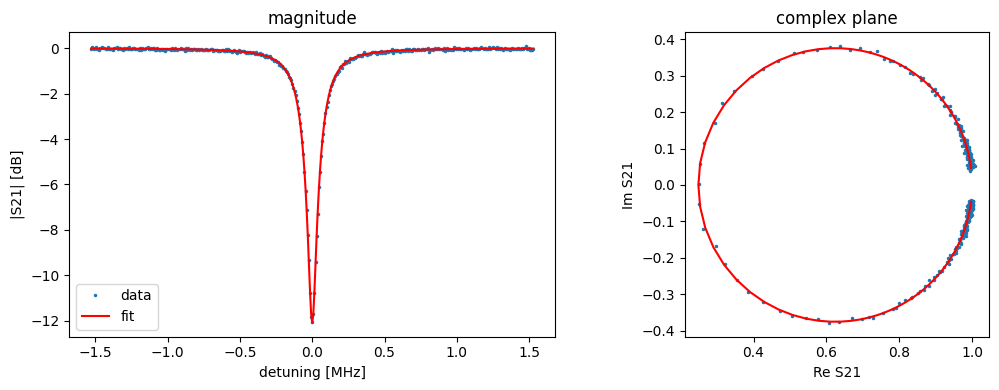

In [5]:
f0, ki, kc = 60e6, 0.3e6, 0.9e6           # kappa = 1.2 MHz
configure_resonator(LANE, f0, ki, kc)

fwhm = _SHADOW[LANE]['kappa']/(2*np.pi)          # linewidth in Hz
fspan = np.linspace(f0 - 8*fwhm, f0 + 8*fwhm, 401)
s21 = measure_s21(fspan) if SYNTHETIC else np.array([measure_s21(f) for f in fspan])

params, model = fit_notch(fspan, s21)
print(f"programmed:  kappa={ (ki+kc)/1e6:.3f} MHz  kappa_c={kc/1e6:.3f}  "
      f"Q={q_from_c1(_SHADOW[LANE]['C1'], f0, FS_HZ):.0f}")
print(f"fitted    :  kappa={params['kappa']/1e6:.3f} MHz  "
      f"kappa_c={params['kappa_c']/1e6:.3f}  Q={params['Q_loaded']:.0f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot((fspan-f0)/1e6, 20*np.log10(np.abs(s21)+1e-6), '.', ms=3, label='data')
ax[0].plot((fspan-f0)/1e6, 20*np.log10(np.abs(model(fspan))+1e-6), 'r-', label='fit')
ax[0].set_xlabel('detuning [MHz]'); ax[0].set_ylabel('|S21| [dB]'); ax[0].legend()
ax[1].plot(s21.real, s21.imag, '.', ms=3); ax[1].plot(model(fspan).real, model(fspan).imag, 'r-')
ax[1].set_xlabel('Re S21'); ax[1].set_ylabel('Im S21'); ax[1].set_aspect('equal')
ax[0].set_title('magnitude'); ax[1].set_title('complex plane'); fig.tight_layout()

## 5 · §7.2 — Ringdown → $\tau$

Charge on resonance, cut the drive, fit the decaying envelope. Expect
$\tau = 1/(-\ln C_1\, f_s)$ (per-clock $C_1$ decay). The $(1-C_1)$ form is the
high-Q limit; a small DC floor from the `cmult` round-half-up bias sits under it.

tau fitted  = 157.98 ns  (39.49 clocks)
tau exact   = 158.03 ns  (approx (1-C1): 160.04 ns)


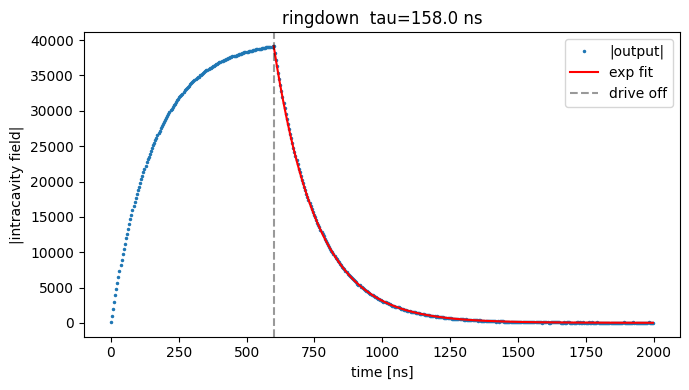

In [6]:
# broader resonator so tau (~40 clocks) fits comfortably in the capture;
# high-Q resonators ring for many tau — capture N >> tau or lower Q to fit.
configure_resonator(LANE, f0, kappa_i_hz=3e6, kappa_c_hz=9.5e6)  # kappa=12.5 MHz
N, DRIVE = 500, 150
tr = capture_trace(N, drive_on_for=DRIVE)
n = np.arange(N)
t = n / FS_HZ
env = np.abs(tr)

decay = slice(DRIVE, N)
A, tau, c = fit_ringdown(t[decay] - t[DRIVE], env[decay])
C1 = _SHADOW[LANE]['C1']
print(f"tau fitted  = {tau*1e9:.2f} ns  ({tau*FS_HZ:.2f} clocks)")
print(f"tau exact   = {tau_field_from_c1(C1, FS_HZ)*1e9:.2f} ns  "
      f"(approx (1-C1): {tau_field_from_c1(C1, FS_HZ, exact=False)*1e9:.2f} ns)")

plt.figure(figsize=(7,4))
plt.plot(t*1e9, env, '.', ms=3, label='|output|')
plt.plot(t[decay]*1e9, A*np.exp(-(t[decay]-t[DRIVE])/tau)+c, 'r-', label='exp fit')
plt.axvline(t[DRIVE]*1e9, color='k', ls='--', alpha=.4, label='drive off')
plt.xlabel('time [ns]'); plt.ylabel('|intracavity field|'); plt.legend()
plt.title(f'ringdown  tau={tau*1e9:.1f} ns'); plt.tight_layout()

## 6 · §7.3 — Notch depth vs coupling

Hold $\kappa_i$, sweep $\kappa_c$; on-resonance depth should track
$\kappa_c/\kappa$ (critical coupling $\kappa_c=\kappa_i$ → deepest).

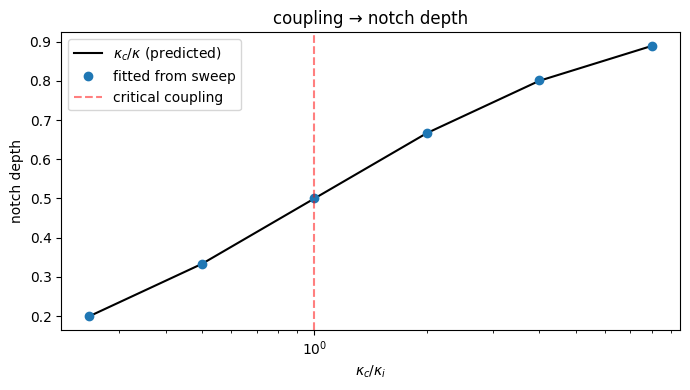

In [7]:
ki_fixed = 0.4e6
kc_list = np.array([0.1, 0.2, 0.4, 0.8, 1.6, 3.2]) * 1e6
depth_meas, depth_pred = [], []
for kc_i in kc_list:
    configure_resonator(LANE, f0, ki_fixed, kc_i)
    fwhm_i = (ki_fixed+kc_i)/(2*np.pi)
    fsp = np.linspace(f0 - 8*fwhm_i, f0 + 8*fwhm_i, 401)
    s = measure_s21(fsp) if SYNTHETIC else np.array([measure_s21(f) for f in fsp])
    p, _ = fit_notch(fsp, s)
    depth_meas.append(p['kappa_c']/p['kappa'])
    depth_pred.append(kc_i/(ki_fixed+kc_i))

plt.figure(figsize=(7,4))
plt.plot(kc_list/ki_fixed, depth_pred, 'k-', label=r'$\kappa_c/\kappa$ (predicted)')
plt.plot(kc_list/ki_fixed, depth_meas, 'o', label='fitted from sweep')
plt.axvline(1, color='r', ls='--', alpha=.5, label='critical coupling')
plt.xscale('log'); plt.xlabel(r'$\kappa_c/\kappa_i$'); plt.ylabel('notch depth')
plt.legend(); plt.title('coupling → notch depth'); plt.tight_layout()

## 7 · §7.4 — The jump (ground → excited)

Drive on the ground resonance, then switch $f_0$ mid-trace. The stored field is
**continuous** (phase-continuous DDS + preserved IIR state, both xsim-confirmed)
and re-rings at the excited frequency while decaying at the unchanged $\kappa/2$.
The instantaneous frequency (phase derivative) shows the clean switch.

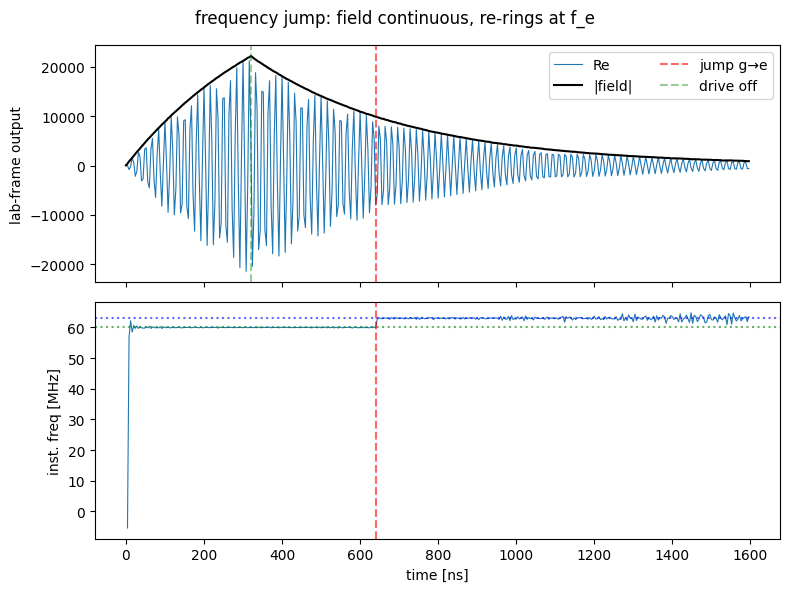

In [8]:
f_g, f_e = 60e6, 63e6
configure_resonator(LANE, f_g, kappa_i_hz=1e6, kappa_c_hz=4e6)  # kappa=5 MHz
N, DRIVE, JUMP = 400, 80, 160
tr = capture_trace(N, drive_on_for=DRIVE, jump_at=JUMP, jump_to_hz=f_e)
n = np.arange(N); t = n/FS_HZ

inst_f = np.diff(np.unwrap(np.angle(tr))) * FS_HZ / (2*np.pi)
fig, ax = plt.subplots(2, 1, figsize=(8,6), sharex=True)
ax[0].plot(t*1e9, tr.real, lw=.8, label='Re'); ax[0].plot(t*1e9, np.abs(tr), 'k', label='|field|')
ax[0].axvline(t[JUMP]*1e9, color='r', ls='--', alpha=.6, label='jump g→e')
ax[0].axvline(t[DRIVE]*1e9, color='g', ls='--', alpha=.4, label='drive off')
ax[0].set_ylabel('lab-frame output'); ax[0].legend(ncol=2)
ax[1].plot(t[1:]*1e9, inst_f/1e6, lw=.8)
ax[1].axhline(f_g/1e6, color='g', ls=':', alpha=.6); ax[1].axhline(f_e/1e6, color='b', ls=':', alpha=.6)
ax[1].axvline(t[JUMP]*1e9, color='r', ls='--', alpha=.6)
ax[1].set_ylabel('inst. freq [MHz]'); ax[1].set_xlabel('time [ns]')
fig.suptitle('frequency jump: field continuous, re-rings at f_e'); fig.tight_layout()

## 8 · §7.5 — Fake $T_1$

Program the ground→excited jump to fire from the tProc at a precomputed time
(here emulated by `jump_at`); the readout then follows the programmed decay.
On hardware, drive the jump from a tProc-timed trigger (see the triggered
frequency-select planned for v4 for a phase-continuous persistent switch;
today's chirp trigger sweeps-and-returns, and a register write is not
time-deterministic).

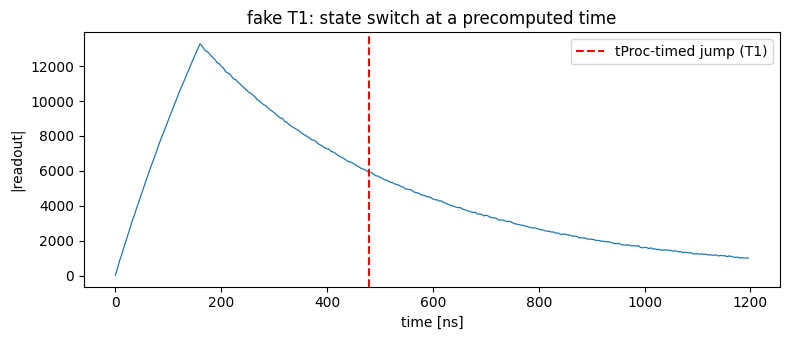

In [9]:
configure_resonator(LANE, f_g, kappa_i_hz=1e6, kappa_c_hz=4e6)
T1_samples = 120
tr = capture_trace(300, drive_on_for=40, jump_at=T1_samples, jump_to_hz=f_e)
t = np.arange(len(tr))/FS_HZ
plt.figure(figsize=(8,3.5))
plt.plot(t*1e9, np.abs(tr), lw=.9)
plt.axvline(t[T1_samples]*1e9, color='r', ls='--', label='tProc-timed jump (T1)')
plt.xlabel('time [ns]'); plt.ylabel('|readout|'); plt.legend()
plt.title('fake T1: state switch at a precomputed time'); plt.tight_layout()

---
### Going to hardware
Flip `SYNTHETIC=False`, set `FS_HZ`/`GEN_CH`/`RO_CH`, and implement `measure_s21`
(CW tone + averaged readout) and `capture_trace` (raw decimated buffer). The
analysis and the register mapping are unchanged. If fits disagree with the
programmed values, dump the raw captured trace first (house rule) — check the
probe/kidsim frequency mapping and that the fabric `FS_HZ` is right, since every
rate scales with it.

---
## Appendix: Mathematical Framework
### Theoretical Mapping: From Continuous Resonator to Digital IIR Filter

#### 1. Continuous-Time Physical Model
A quasi-monochromatic resonator driven near its resonance frequency $\omega_0$ is described by Input-Output Theory [1, 2]. The time evolution of the intra-cavity field $a(t)$ under an external drive $s_{in}(t)$ is given by the differential equation:

$$\frac{da(t)}{dt} = -\left(i\Delta\omega + \frac{\kappa}{2}\right) a(t) + \sqrt{\kappa_{in}}\, s_{in}(t)$$

where $\Delta\omega = \omega - \omega_0$ is the detuning, $\kappa = \kappa_{int} + \kappa_{in}$ is the total energy decay rate of the resonator, and $\kappa_{in}$ represents the coupling rate to the transmission line [2].

In a ringdown experiment (free decay after the drive pulse is turned off, $s_{in}(t) = 0$), the complex envelope of the field evolves as:

$$a(t) = a(0) \, e^{-i\Delta\omega t} e^{-\frac{\kappa}{2}t} = a(0) \, e^{-i\Delta\omega t} e^{-t/\tau}$$

where $\tau = \frac{2}{\kappa}$ is the characteristic amplitude decay time.

#### 2. Discrete Implementation (1st-Order IIR Filter)
In the digital signal processing (DSP) inside the FPGA, the first-order dynamics of the resonator are emulated by discretizing the differential equation using a first-order Infinite Impulse Response (IIR) filter [3]:

$$y[n] = C_0 x[n] + C_1 y[n-1]$$

where $x[n]$ is the sampled input signal, $y[n]$ is the internal state (or output) of the resonator, and $T_s = 1/f_s$ is the sampling period of the FPGA clock.

During the ringdown phase ($x[n] = 0$), the homogeneous response of the filter at step $n$ reduces to:

$$y[n] = y[0] \cdot (C_1)^n$$

Expressing the time in the continuous domain using $t = n T_s = \frac{n}{f_s}$, the equivalent continuous-time envelope is:

$$y(t) = y(0) \cdot \left(C_1\right)^{t f_s} = y(0) \cdot e^{t f_s \ln(C_1)}$$

#### 3. Explicit Mapping Between Coefficients ($C_0, C_1$) and Physical Parameters
By equating the temporal attenuation of the continuous model $e^{-t/\tau}$ with that of the discrete filter $e^{t f_s \ln(C_1)}$, we establish the identity:

$$-\frac{1}{\tau} = -\frac{\kappa}{2} = f_s \ln(C_1)$$

From this relationship, the exact conversion formulas are derived:

* **Amplitude decay time ($\tau$):**
  $$\tau = -\frac{1}{f_s \ln(C_1)}$$

* **Energy linewidth ($\kappa$):**
  $$\kappa = -2 f_s \ln(C_1)$$

* **Loaded Quality Factor ($Q$):**
  $$Q = \frac{\omega_0}{\kappa} = -\frac{\pi f_0}{f_s \ln(C_1)}$$

* **Input Coupling / Gain ($C_0$):**
  The input coefficient $C_0$ maps the physical coupling rate $\sqrt{\kappa_{in}}$ scaled by the integration interval $T_s$:
  $$C_0 \approx \sqrt{\kappa_{in}} \cdot T_s = \frac{\sqrt{\kappa_{in}}}{f_s}$$






---
### References

* **[1] Gardiner, C. W., & Collett, M. J. (1985).** Input and output in damped quantum systems: Quantum stochastic differential equations and the master equation. *Physical Review A*, 31(6), 3761.
* **[2] Khalil, M. S., et al.** An analysis method for asymmetric superconducting resonators from transmission measurements. *Journal of Applied Physics* 111.5 (2012): 054510.
* **[3] Zmuidzinas, J. (2012).** Superconducting microresonators: Physics and applications. *Annual Review of Condensed Matter Physics*, 3(1), 169-214.
* **[4] Stefanazzi, L., et al. (2022).** The QICK (Quantum Instrumentation Control Kit): Readout and control for qubits and superconducting circuits. *Review of Scientific Instruments*, 93(4), 044709.